# Praktikum 2 - Support Vector Regression (SVR) pada Data Posisi dan Gaji

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

## Langkah 1 & 2: Mengimpor Library dan Dataset `Posisi_gaji.csv`

Pada praktikum kedua ini saya membangun model regresi non-linier menggunakan **Support Vector Regression (SVR)** dengan kernel *Radial Basis Function* (`rbf`) untuk memodelkan hubungan eksponensial antara tingkat jabatan (`Level` 1 s.d. 10) dan besaran gaji tahunan (`Gaji` dalam dolar) pada dataset `Posisi_gaji.csv`.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Mengimpor dataset
dataset = pd.read_csv('Posisi_gaji.csv')
X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values  # Ubah menjadi satu kolom saja

dataset

,Posisi,Level,Gaji
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


Dari tabel di atas terlihat bahwa kenaikan gaji dari `Level 1` (*Business Analyst*, `$45,000`) hingga `Level 6` (*Region Manager*, `$150,000`) berlangsung cukup landai, tetapi melonjak secara eksponensial mulai dari `Level 8` (*Senior Partner*, `$300,000`), `Level 9` (*C-level*, `$500,000`), hingga `Level 10` (*CEO*, `$1,000,000`). Pola melengkung tajam seperti ini tidak cocok jika didekati dengan garis lurus biasa.

## Langkah 3 & 4: Feature Scaling dan Fitting SVR (`kernel='rbf'`)

Karena algoritma berbasis *Support Vector* menghitung jarak di dalam fungsi kernel dan sangat peka terhadap perbedaan skala angka (`Level` bernilai `1 - 10` sedangkan `Gaji` bernilai `45.000 - 1.000.000`), kedua variabel `X` dan `y` terlebih dahulu distandardisasi menggunakan `StandardScaler` sebelum dilatih dengan `SVR(kernel='rbf')`.

In [2]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1))

# Fitting SVR ke dataset
from sklearn.svm import SVR
regressor = SVR(kernel='rbf')
regressor.fit(X, y)

,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,1.0
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


## Langkah 5: Visualisasi Hasil SVR

Membuat *grid* titik `X_grid` dengan resolusi `0.01` untuk menggambar kurva halus hasil prediksi SVR (garis biru) terhadap titik observasi asli (titik merah).

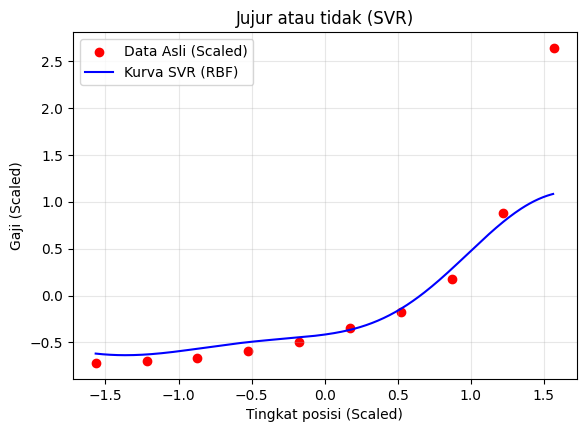

In [3]:
# Visualisasi hasil SVR (resolusi tinggi dan kurva yang lebih halus)
X_grid = np.arange(float(np.min(X)), float(np.max(X)), 0.01).reshape(-1, 1)
plt.figure(figsize=(6.5, 4.5))
plt.scatter(X, y, color='red', label='Data Asli (Scaled)')
plt.plot(X_grid, regressor.predict(X_grid), color='blue', label='Kurva SVR (RBF)')
plt.title('Jujur atau tidak (SVR)')
plt.xlabel('Tingkat posisi (Scaled)')
plt.ylabel('Gaji (Scaled)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Langkah 6 & 7: Prediksi Hasil untuk Tingkat Posisi 6.5

Untuk memprediksi gaji kandidat pada tingkat posisi `6.5` (di antara *Region Manager* level 6 dan *Partner* level 7), nilai `[[6.5]]` ditransformasikan terlebih dahulu menggunakan `sc_X.transform()`, diprediksi dengan `regressor.predict()`, lalu dikembalikan ke satuan dolar asli menggunakan `sc_y.inverse_transform()`.

In [4]:
# Prediksi hasil
# Buat array 2D yang berisi tingkat posisi yang akan diprediksi
tingkat_posisi_prediksi = np.array([[6.5]])
# Penskalaan fitur untuk data yang akan diprediksi
tingkat_posisi_prediksi = sc_X.transform(tingkat_posisi_prediksi)
# Melakukan prediksi menggunakan model SVR
gaji_prediksi = regressor.predict(tingkat_posisi_prediksi)
# Kembalikan hasil prediksi ke skala aslinya
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi.reshape(-1, 1))

# Menampilkan hasil prediksi
print("Prediksi Gaji untuk Tingkat Posisi 6.5:", gaji_prediksi[0])

Prediksi Gaji untuk Tingkat Posisi 6.5: [170370.0204065]


## Langkah 8: Evaluasi Model SVR (MAE, MSE, RMSE, dan $R^2$)

Menghitung metrik kesalahan **MAE**, **MSE**, **RMSE**, dan koefisien determinasi **$R^2$** antara nilai aktual `y` dan hasil prediksi `regressor.predict(X)`.

In [5]:
# Evaluasi model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y.ravel()
y_pred = regressor.predict(X)

# Menghitung MAE
mae = mean_absolute_error(y_actual, y_pred)

# Menghitung MSE
mse = mean_squared_error(y_actual, y_pred)

# Menghitung RMSE
rmse = np.sqrt(mse)

# Menghitung R-squared
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 0.22299274095734414
MSE: 0.24839989293792014
RMSE: 0.4983973243687411
R-squared: 0.7516001070620798


### Analisis Hasil Praktikum 2

Berdasarkan hasil pemodelan dan evaluasi SVR di atas:

1. **Prediksi Tingkat Posisi 6.5:** Model SVR dengan kernel `rbf` memprediksi gaji untuk kandidat pada posisi level `6.5` sebesar **`$170,370.02`** (`[170370.0204065]`). Nilai ini sangat realistis dan berada tepat di antara gaji *Region Manager* (`Level 6 = $150,000`) dan *Partner* (`Level 7 = $200,000`).
2. **Perilaku Kurva SVR terhadap Outlier (`CEO` Level 10):** Pada grafik terlihat bahwa kurva biru mengikuti titik-titik merah dengan sangat rapat dari `Level 1` hingga `Level 9`, namun melengkung datar di bawah titik `Level 10` (`CEO` dengan gaji `$1,000,000`). Hal ini terjadi karena dengan parameter regularisasi bawaan (`C = 1.0`), SVR memperlakukan lonjakan ekstrem gaji CEO pada `Level 10` sebagai *outlier* di luar pipa margin $\varepsilon$ agar kurva tidak mengalami *overfitting*.
3. **Metrik Evaluasi:** Pada skala terstandardisasi, diperoleh nilai `MAE = 0.2230`, `MSE = 0.2484`, `RMSE = 0.4984`, dan `R-squared = 0.7516` (`75.16%`). Sebagian besar selisih error tersebut berasal dari satu titik ekstrem `Level 10` (*CEO*), sedangkan untuk `Level 1` hingga `Level 9` kurva SVR sudah sangat presisi mengikuti pola kenaikan gaji non-linier.